[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmedelshazly27/mizan-kuwait-energy-toolkit/blob/main/notebooks/08-system-and-water.ipynb)

In [1]:
# On Colab: clone the repository and install it (inputs are committed, no credentials needed).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("mizan-kuwait-energy-toolkit"):
    !git clone --depth 1 https://github.com/ahmedelshazly27/mizan-kuwait-energy-toolkit.git
    %pip install -q -e "mizan-kuwait-energy-toolkit[pv,econ,system]" matplotlib
    os.chdir("mizan-kuwait-energy-toolkit")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from kwtk import viz; viz.style()

# 8. Kuwait's system and water

The system model dispatches Kuwait's fleet in three zones with MEW's measured fuel
costs and must-run floors for distillation. A plant's value to the system is the fuel
it avoids; its limit is the hours the system cannot absorb it.

In [2]:
from kwtk.engines import system, water
st = system.station_table(2023)
st[['gen_mwh', 'kd_per_mwh', 'mmbtu_per_mwh', 'min_monthly_avg_mw']].round(2).sort_values('kd_per_mwh')

variable,gen_mwh,kd_per_mwh,mmbtu_per_mwh,min_monthly_avg_mw
plant_id,,,,
zour-north,13994000.0,16.76,7.44,1421.16
shuaiba-north,3830000.0,20.20,8.33,10.34
shuaiba-south,3755000.0,22.03,10.52,315.19
sabiya,27855000.0,25.75,8.12,1382.48
zour-south,23376000.0,29.36,8.94,1554.21
doha-west,11090000.0,43.52,10.38,819.57
doha-east,3575000.0,53.98,13.20,83.36
shuwaikh,370000.0,60.29,24.42,0.00


In [3]:
system.zone_shares().round(3)

zone
central    0.475
north      0.160
south      0.365
dtype: float64

In [4]:
from kwtk.plant.evaluate import evaluate
r = evaluate('configs/examples/shagaya-scale-pv-tracker.yaml')['result']['system_context']
pd.Series(r['displaced_mwh_by_station']).div(1e3).round(0).rename('GWh displaced').sort_values(ascending=False)

sabiya           1366.0
zour-south       1007.0
shuaiba-north     462.0
shuaiba-south     180.0
zour-north         46.0
doha-west           0.0
doha-east           0.0
shuwaikh            0.0
Name: GWh displaced, dtype: float64

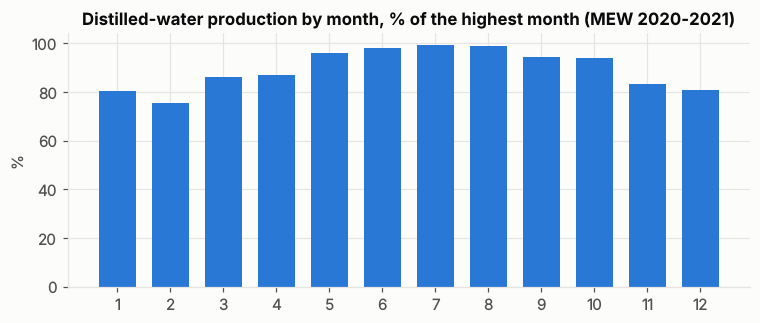

In [5]:
p = water.seasonal_profile()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(p.index, p.values * 100, width=0.7); ax.set_xticks(range(1, 13))
ax.set_title('Distilled-water production by month, % of the highest month (MEW 2020-2021)'); ax.set_ylabel('%')
plt.show()

In [6]:
ro = evaluate('configs/examples/shagaya-scale-pv-ro.yaml')['result']
ro['storage']['water']

{'ro1': {'water_m3_per_year': 81036803.2892666,
  'energy_mwh_per_year': 432736.52956468356,
  'unmet_water_m3_per_year': 799782.2408575894},
 'from_grid_mwh_per_year': 201157.81452646514}